# Fronthaul Load of Functional Splits 7-1, 7.2x Cat A / Cat B and Option 8 in a Cell-Free Downlink

This notebook compares the fronthaul load of four lower-layer functional splits in the same cell-free downlink.
The channel is drawn by Monte Carlo drops from the TR 38.901 UMi-Street Canyon model (no ray tracing / digital twin).
Each UE reports a CQI, the MAC looks up the MCS from that CQI, the PDSCH is sent through the split's fronthaul with
a given compression scheme, and the UE decodes it. For every (split, compression) pair we record the fronthaul load
and what it costs in throughput, and we plot the equalized constellations at the UE.

| Split | Spec | O-DU does | Fronthaul carries (per O-RU link) | O-RU does | Compression here | Code |
|---|---|---|---|---|---|---|
| Option 7-1 | TR 38.801 §11.1.2.7, TR 38.816 §4.2 / Annex A | everything up to precoding and RE mapping | frequency-domain IQ of every antenna, **whole carrier, every symbol**, regardless of scheduling | IFFT + CP | none standardized: uniform fixed point 2×w bit | `category="7-1"` |
| 7.2x Cat A | O-RAN CUS v22 §4.2 | same as 7-1, plus IQ compression | per antenna stream, only PRBs that carry data (sections), plus C-plane | decompression, IFFT + CP | BFP / block scaling / μ-law (Annex A.1–A.3) | `category="A"` |
| 7.2x Cat B | O-RAN CUS v22 §4.2 | up to RE mapping (layer domain) | per layer IQ + precoding weights (C-plane SE 11) | precoding, IFFT + CP | BFP / block scaling / μ-law, or **modulation compression** (Annex A.5) | `category="B"` |
| Option 8 | TR 38.801 §11.1.2.8 | the whole PHY incl. IFFT + CP | time-domain IQ of every antenna at the sample rate (incl. guard band) | RF only | none standardized (CPRI): uniform fixed point 2×w bit | `category="8"` |

Without compression the four splits put **bit-identical signals on the air** (unit tests), so every difference in
the results comes from the fronthaul. Option 7-1 and Cat A place the same functions in the O-DU; they differ only in
the interface: 7-1 always streams the whole carrier, uncompressed by O-RAN methods and without sections or C-plane.

```
Drop (TR 38.901 UMi): O-RU grid + random UEs → LoS/NLoS, path loss, shadowing, clusters → static channel per drop
   │
O-DU: BD precoding over all O-RU antennas (TDD reciprocity, ideal CSI), scaled to the per-O-RU power limit
   │
Measurement slot: precoded CSI-RS + CSI-IM ─ fronthaul (split × compression) ─ O-RUs ─ channel ─ UE: CMR / NZP-IMR / CSI-IM → CQI → UCI
   │
MAC: CQI → MCS by table lookup (no OLLA)
   │
Data slots: PDSCH ─ fronthaul (split × compression) ─ O-RUs ─ channel ─ UE: DMRS LS → LMMSE → LDPC → CRC
   │
Record: throughput, BLER, CQI vs genie CQI, U-plane SQNR, fronthaul load per O-RU link (20 MHz simulated, 100 MHz scaled)
```

| Section | Content |
|---|---|
| 0–1 | Switches, initialization |
| 2 | The cell-free drop: layout, LoS/NLoS, link gains |
| 3 | Monte Carlo closed loop over all splits and compression schemes (paired drops and seeds) |
| 4 | Throughput vs fronthaul load; minimum load per split without throughput loss |
| 5 | Equalized constellations at the UE |
| 6 | How the load scales with antennas per O-RU and PRB utilization (analytic) |
| 7 | Summary and modelling notes |

## 0. Switches

- **Scenario**: `NUM_ORU` O-RUs on a square grid inside an `AREA_M` × `AREA_M` area, 10 m high, each with `NUM_ORU_ANT`
  TX chains; with the defaults the O-RU spacing is the UMi inter-site distance of 200 m (TR 38.901 Table 7.2-1).
  `NUM_UE` static outdoor UEs are dropped uniformly (at least 10 m from every O-RU, Table 7.2-1). All O-RUs serve all UEs
  (full cooperation, centralized BD). 4 UEs × 1 layer use DMRS Type 1 single-symbol ports 0–3 and fit the CSI-RS pattern.
- **Link adaptation**: CQI table and MCS table 2 (256QAM). `CQI_SOURCE = "csi-rs"` sends the CSI-RS through each split's
  own fronthaul, so part of the compression distortion shows up in the CQI; `"genie"` uses the true effective channel.
  The MCS is a plain CQI table lookup (OLLA off).
- **`CONFIGS`**: (split, U-plane compression, Cat B weight compression). `("fixed", w)` is uniform fixed point with w bit per
  I/Q (7-1, option 8); `("modulation", 16)` is modulation compression (Cat B only; its bit width follows the MCS).
  `REFERENCE` is the ideal fronthaul, which is the same air interface for every split.
- **Run time**: about 35 s per drop on a T4 with the default list (21 configurations × 4 CSI-RS periods), plus about
  40 s of initialization.

In [1]:
# ================================ Switches ================================
# ---- Cell-free scenario (TR 38.901 UMi-Street Canyon, Monte Carlo drops, no ray tracing) ----
NUM_ORU        = 4             # O-RUs on a square grid inside the area
NUM_ORU_ANT    = 8             # TX chains per O-RU (1 x 4 dual-polarized)
AREA_M         = 400.0         # side of the square area [m]; 4 O-RUs -> 200 m spacing = UMi ISD (TR 38.901 Table 7.2-1)
TX_POWER_DBM   = 35.0          # maximum transmit power per O-RU over the 20 MHz carrier
ABSOLUTE_DELAY = True          # TR 38.901 §7.6.9: add d_3D / c to every link (O-RUs are at different distances)
NUM_UE         = 4             # co-scheduled UEs, all served by all O-RUs
NUM_UE_ANT     = 2
LAYERS_PER_UE  = 1

# ---- Link adaptation ----
MCS_TABLE  = 2                 # MCS table 2 (up to 256QAM) and CQI table 2
CQI_SOURCE = "csi-rs"          # "csi-rs": CSI-RS / CSI-IM through each split's fronthaul; "genie": true effective channel

# ---- Monte Carlo ----
NUM_DROPS        = 20
NUM_PERIODS      = 4           # CSI-RS periods per drop
SLOTS_PER_PERIOD = 7           # data slots per period (plus 1 measurement slot)
SEED             = 2026        # drop i uses seed SEED + i for positions, LoS, shadowing, fading, bits and noise

# ---- Fronthaul configurations: (split, U-plane compression, Cat B weight compression or None) ----
REFERENCE = ("A", ("ideal", 16), None)       # ideal fronthaul: identical air interface for every split
CONFIGS = [
    ("7-1", ("fixed", 16), None), ("7-1", ("fixed", 10), None), ("7-1", ("fixed", 8), None), ("7-1", ("fixed", 6), None),
    ("A", ("bfp", 9), None), ("A", ("bfp", 7), None), ("A", ("bfp", 5), None),
    ("A", ("block_scaling", 5), None), ("A", ("mu_law", 5), None),
    ("B", ("bfp", 9), ("bfp", 9)), ("B", ("bfp", 7), ("bfp", 7)), ("B", ("bfp", 5), ("bfp", 5)),
    ("B", ("block_scaling", 5), ("block_scaling", 5)), ("B", ("mu_law", 5), ("mu_law", 5)),
    ("B", ("modulation", 16), ("bfp", 9)), ("B", ("modulation", 16), ("bfp", 7)),
    ("8", ("fixed", 16), None), ("8", ("fixed", 10), None), ("8", ("fixed", 8), None), ("8", ("fixed", 6), None),
]
THROUGHPUT_KEEP = 0.99         # "no throughput loss": at least this fraction of the ideal-fronthaul throughput

# ---- Constellation plot (Section 5) ----
CONSTELLATION_DROP = 0
CONSTELLATION_UE   = None      # None: the UE with the highest CQI in that drop (ideal fronthaul)
CONSTELLATION_MCS  = None      # None: MCS from each configuration's own CQI; e.g. 27 forces 256QAM for all UEs
CONSTELLATION_CONFIGS = {
    "7-1": [(("fixed", 16), None), (("fixed", 8), None), (("fixed", 6), None)],
    "A":   [(("bfp", 9), None), (("bfp", 7), None), (("bfp", 5), None)],
    "B":   [(("bfp", 9), ("bfp", 9)), (("bfp", 5), ("bfp", 5)), (("modulation", 16), ("bfp", 7))],
    "8":   [(("fixed", 16), None), (("fixed", 8), None), (("fixed", 6), None)],
}

SAVE_RESULTS = True            # rows, metadata, source snapshot and figures under results/split_fronthaul_load_<date>/
DEVICE = "cuda:0"

## 1. Initialization

One `ClosedLoopDownlink` per split (O-DU, fronthaul links, O-RUs, channel, UEs, CSI-RS, CQI reporter, link adaptation).
All four share **one channel source**, so in every drop the four splits see exactly the same channel; the compression
scheme is switched with `set_compression` on the same drop, and every configuration starts from the same random seed
(same bits, same noise).

Two cell-free options are switched on (`oran/config.py`):
- `per_oru_power`: the BD precoder is scaled so that the strongest O-RU transmits exactly its maximum power
  (each O-RU has its own power amplifier); the scaling is common to all layers, so the BD nulls are unchanged.
- `fronthaul_agc`: the O-DU sets the fixed-point gain of each antenna stream from the actual antenna power (known from
  the precoder). In cell-free the antenna powers of different O-RUs differ by tens of dB; uniform quantizers (7-1, option 8)
  would otherwise clip or waste resolution. Block-adaptive methods (BFP, block scaling, μ-law) hardly depend on it.

In [2]:
import os, sys, time, warnings
from dataclasses import replace

ROOT = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(ROOT, "oran")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
warnings.filterwarnings("ignore")

import numpy as np
import torch
import matplotlib.pyplot as plt
from sionna.phy import config as sionna_config
from sionna.phy.mapping import Constellation

torch.set_grad_enabled(False)

from oran import ORANConfig, CompressionConfig, ClosedLoopDownlink, LinkAdaptationConfig, UMiConfig
from oran.bler_model import mcs_entry
from oran.fronthaul import fronthaul_rate, tr38816_rate
from oran.umi_channel import snr_scale
from common.runio import Run

sionna_config.device = DEVICE
db = lambda x: 10 * np.log10(np.maximum(np.asarray(x, dtype=float), 1e-30))

SPLITS = ["7-1", "A", "B", "8"]
SPLIT_NAME = {"7-1": "Option 7-1", "A": "7.2x Cat A", "B": "7.2x Cat B", "8": "Option 8"}
COLOR = {"7-1": "#2a78d6", "A": "#eb6834", "B": "#1baf7a", "8": "#eda100"}   # fixed categorical order
MARKER = {"7-1": "o", "A": "s", "B": "^", "8": "D"}                          # second encoding besides color
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
NUM_PRB_100MHZ = 273

base = ORANConfig(
    channel_model="umi", num_oru=NUM_ORU, num_oru_ant=NUM_ORU_ANT, num_ue=NUM_UE, num_ue_ant=NUM_UE_ANT,
    num_layers_per_ue=LAYERS_PER_UE, mcs_table=MCS_TABLE, cqi_source=CQI_SOURCE, precoder="bd",
    per_oru_power=True, fronthaul_agc=True, device=DEVICE,
    umi=UMiConfig(area=[0.0, AREA_M, 0.0, AREA_M], tx_power_dbm=TX_POWER_DBM, absolute_delay=ABSOLUTE_DELAY))
la_cfg = LinkAdaptationConfig(olla=False)       # MCS = CQI table lookup


def comp_of(c):
    return CompressionConfig(*c) if c is not None else CompressionConfig("bfp", 9)


t0 = time.time()
loops = {}
for split in SPLITS:
    first = next(c for c in CONFIGS if c[0] == split)
    loops[split] = ClosedLoopDownlink(replace(base, category=split, uplane=comp_of(first[1]), bfw=comp_of(first[2])),
                                      la_cfg)
channel = loops["A"].rt_channel                 # oran.umi_channel.UMiChannel, shared by all splits
for split in SPLITS:
    loops[split].sim.channel.model = channel
print(f"Initialization {time.time() - t0:.1f} s; usable MCS (table {MCS_TABLE}): {loops['A'].la.allowed_mcs.tolist()}")
print(f"Carrier: {base.subcarrier_spacing} kHz SCS, {base.num_prb} PRB, {base.carrier_frequency / 1e9:.1f} GHz; "
      f"load also scaled to {NUM_PRB_100MHZ} PRB (100 MHz)")
print(f"Cell-free: {NUM_ORU} O-RU × {NUM_ORU_ANT} TX = {base.num_tx_ant} antennas; {NUM_UE} UE × {NUM_UE_ANT} RX, "
      f"{LAYERS_PER_UE} layer(s) each ({base.num_layers} layers)")
print("O-RU positions [m]:", channel.oru_positions.round(1).tolist())
print(f"Link budget: {TX_POWER_DBM} dBm per O-RU, NF {base.umi.noise_figure_db} dB → total P_RE / N0 = "
      f"{db(snr_scale(base)):.1f} dB (before path loss)")
print(f"{len(CONFIGS) + 1} fronthaul configurations × {NUM_DROPS} drops × {NUM_PERIODS} CSI-RS periods "
      f"of {SLOTS_PER_PERIOD + 1} slots")

Initialization 38.1 s; usable MCS (table 2): [3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27]
Carrier: 30 kHz SCS, 51 PRB, 3.5 GHz; load also scaled to 273 PRB (100 MHz)
Cell-free: 4 O-RU × 8 TX = 32 antennas; 4 UE × 2 RX, 1 layer(s) each (4 layers)
O-RU positions [m]: [[100.0, 100.0, 10.0], [300.0, 100.0, 10.0], [100.0, 300.0, 10.0], [300.0, 300.0, 10.0]]
Link budget: 35.0 dBm per O-RU, NF 9.0 dB → total P_RE / N0 = 133.4 dB (before path loss)
21 fronthaul configurations × 20 drops × 4 CSI-RS periods of 8 slots


## 2. The cell-free drop

TR 38.901 §7.5 for every (UE, O-RU) link (Sionna `tr38901.UMi`, parameter tables V16.1.0, unchanged up to the V18.0.0 in
the repository): LoS probability (Table 7.4.2-1), UMi-Street Canyon path loss (Table 7.4.1-1), shadow fading and the other
large-scale parameters (Table 7.5-6), clusters and rays with angles given by the geometry. With `ABSOLUTE_DELAY` each link
also gets its propagation delay d_3D / c (§7.6.9), and each UE takes the first path over all O-RUs as its timing reference.
The UE is static: one small-scale realization per drop, used in all slots of that drop.

Left: O-RUs, the UEs of the first drop (lines: solid = LoS, dotted = NLoS) and the UE positions of all drops (gray).
Right: link gain (path loss + shadowing + antennas, averaged over antenna pairs and subcarriers) of the first drop.

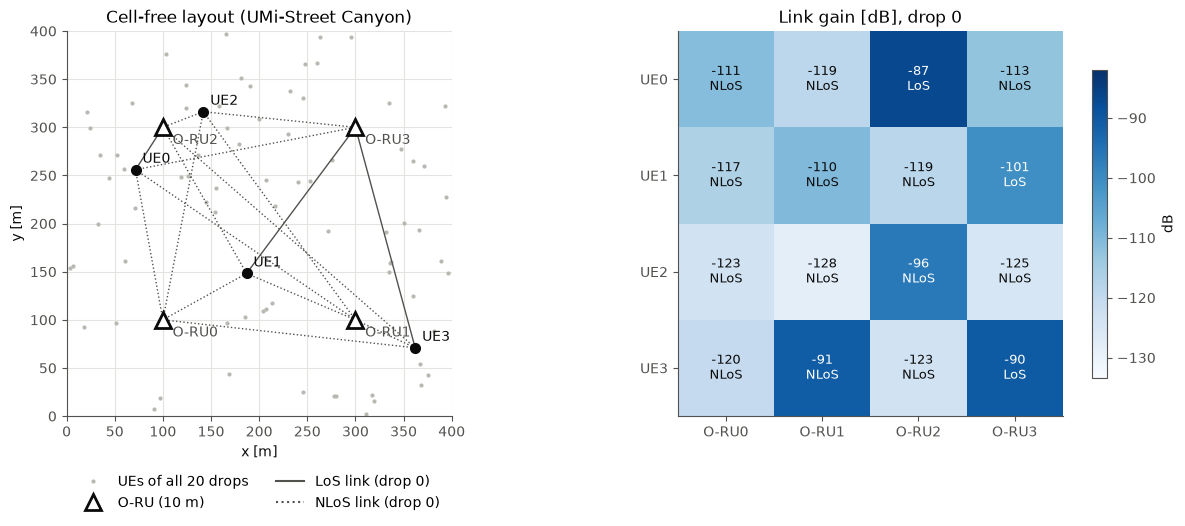

Wideband SNR per RX antenna (no beamforming gain) [dB]: [40.400001525878906, 27.200000762939453, 30.899999618530273, 39.70000076293945]
First-path delay of each O-RU relative to the UE timing [µs]:
[[0.352 0.746 0.    0.599]
 [0.    0.078 0.251 0.299]
 [0.582 0.741 0.    0.378]
 [0.65  0.    0.931 0.562]]
Share of the total power budget used by each O-RU after the per-O-RU scaling: [0.017000000923871994, 0.32199999690055847, 1.0, 0.675000011920929]


In [3]:
drop_positions = [channel.drop_ues(NUM_UE, SEED + i) for i in range(NUM_DROPS)]
channel.set_ue_positions(drop_positions[0], seed=SEED)
gain = channel.link_gain_db()                               # [K, O]
oru = channel.oru_positions

fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), gridspec_kw={"width_ratios": [1.05, 1]})
ax = axes[0]
allp = np.concatenate(drop_positions)
ax.plot(allp[:, 0], allp[:, 1], ".", color="#b8b7b1", ms=4, label=f"UEs of all {NUM_DROPS} drops")
for k, p in enumerate(drop_positions[0]):
    for o in range(NUM_ORU):
        ax.plot([p[0], oru[o, 0]], [p[1], oru[o, 1]], "-" if channel.los[k, o] else ":", color=INK2, lw=1.0)
    ax.plot(p[0], p[1], "o", color=INK, ms=7)
    ax.annotate(f"UE{k}", p[:2], xytext=(5, 5), textcoords="offset points", color=INK)
ax.plot(oru[:, 0], oru[:, 1], "^", color=INK, ms=12, mfc="white", mew=2, label="O-RU (10 m)")
for o in range(NUM_ORU):
    ax.annotate(f"O-RU{o}", oru[o, :2], xytext=(7, -12), textcoords="offset points", color=INK2)
ax.plot([], [], "-", color=INK2, label="LoS link (drop 0)"); ax.plot([], [], ":", color=INK2, label="NLoS link (drop 0)")
ax.set_xlim(0, AREA_M); ax.set_ylim(0, AREA_M); ax.set_aspect("equal")
ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]"); ax.set_title("Cell-free layout (UMi-Street Canyon)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)

ax = axes[1]
vmin, vmax = gain.min() - 5, gain.max() + 5
im = ax.imshow(gain, cmap="Blues", vmin=vmin, vmax=vmax)
for k in range(NUM_UE):
    for o in range(NUM_ORU):
        ax.text(o, k, f"{gain[k, o]:.0f}\n{'LoS' if channel.los[k, o] else 'NLoS'}", ha="center", va="center",
                color="white" if (gain[k, o] - vmin) / (vmax - vmin) > 0.55 else INK, fontsize=9)
ax.set_xticks(range(NUM_ORU), [f"O-RU{o}" for o in range(NUM_ORU)])
ax.set_yticks(range(NUM_UE), [f"UE{k}" for k in range(NUM_UE)])
ax.grid(False); ax.set_title("Link gain [dB], drop 0")
fig.colorbar(im, ax=ax, shrink=0.8, label="dB")
plt.tight_layout(); plt.show()
fig_layout = fig

sim_a = loops["A"].sim
w = sim_a.odu.precoder(sim_a.channel.csi(sim_a.channel.sample(1), sim_a.csi_symbol))
print("Wideband SNR per RX antenna (no beamforming gain) [dB]:", channel.wideband_snr_db().round(1).tolist())
print("First-path delay of each O-RU relative to the UE timing [µs]:")
print((channel.delay_offset * 1e6).round(3))
print("Share of the total power budget used by each O-RU after the per-O-RU scaling:",
      (NUM_ORU * loops["A"].sim.odu.oru_power(w)[0]).cpu().numpy().round(3).tolist())

## 3. Monte Carlo closed loop

For every drop: place the UEs and generate the channel once, then for every configuration (same seed):
`NUM_PERIODS` CSI-RS periods, each = measurement slot (CSI-RS through the fronthaul → CQI) + `SLOTS_PER_PERIOD` data slots
with the MCS looked up from that CQI (`ClosedLoopDownlink.run_drop`).

Recorded per (drop, configuration): throughput of first transmissions (data slots), BLER, mean MCS, CQI and genie CQI,
measured post-equalization SINR, U-plane SQNR, and the fronthaul load of one O-RU link at 20 MHz (simulated) and 100 MHz
(273 PRB), including eCPRI and Ethernet headers:

| Split | Load model (`oran/fronthaul.py`) |
|---|---|
| 7-1 | `split71_rate`: antennas × all subcarriers × symbols/s × 2w (TR 38.816 Annex A formula without its fixed overhead), eCPRI IQ messages, no C-plane |
| Cat A | `uplane_rate` + `cplane_rate`: per antenna stream, PRB blocks with udCompParam, section type 1 |
| Cat B | per layer + SE 11 weights; with modulation compression `modulation_rate`: 24·Qm/2 bit per PRB on data symbols, 24 bit on DMRS symbols, extra SE 5 / SE 6 and a DMRS section; **follows the MCS of every period** |
| 8 | `option8_rate`: antennas × sample rate (IFFT size × SCS) × 2w, eCPRI IQ messages, no C-plane |

With full cooperation every O-RU link carries the same load, so the network load is `NUM_ORU` × the link load.

In [4]:
LABEL = {"fixed": "{w}-bit", "bfp": "BFP{w}", "block_scaling": "BS{w}", "mu_law": "μ-law{w}",
         "modulation": "ModComp", "ideal": "ideal", "none": "{w}-bit"}


def config_label(split, up, bfw):
    s = LABEL[up[0]].format(w=up[1])
    if split == "B" and up[0] == "modulation":
        s += " / w " + LABEL[bfw[0]].format(w=bfw[1])
    return s


_rate_cache = {}


def link_load(cfg, num_prb, mcs_history):
    """Load of one O-RU link [bit/s] (U-plane, C-plane, total). Modulation compression: mean over the periods' MCS."""
    out = []
    histories = mcs_history if cfg.uplane.method == "modulation" else [None]
    for mcs in histories:
        qm = None if mcs is None else tuple(mcs_entry(cfg.mcs_table, int(m))[0] for m in mcs)
        key = (cfg.category, cfg.uplane.method, cfg.uplane.iq_width, cfg.bfw.method, cfg.bfw.iq_width, num_prb, qm)
        if key not in _rate_cache:
            _rate_cache[key] = fronthaul_rate(cfg, num_prb, qm_per_ue=qm)
        out.append(_rate_cache[key])
    return {"uplane": float(np.mean([r.uplane_total for r in out])),
            "cplane": float(np.mean([r.cplane_total for r in out])),
            "total": float(np.mean([r.total for r in out]))}


def finite(v):
    return None if v is None or not np.isfinite(v) else float(v)


def run_config(drop, seed, positions, split, up, bfw):
    cl = loops[split]
    cl.set_compression(CompressionConfig(*up), comp_of(bfw))
    sionna_config.seed = seed
    res = cl.run_drop(positions, num_batches=NUM_PERIODS, batch_size=SLOTS_PER_PERIOD, warmup_batches=0)
    s = res.summary(cl.cfg.slots_per_second)
    fh = cl.sim.fronthaul_stats()
    mcs_hist = np.asarray(res.mcs)
    l20 = link_load(cl.cfg, cl.cfg.num_prb, mcs_hist)
    l100 = link_load(cl.cfg, NUM_PRB_100MHZ, mcs_hist)
    return {
        "drop": drop, "seed": seed, "split": split, "uplane": list(up), "bfw": None if bfw is None else list(bfw),
        "label": config_label(split, up, bfw), "reference": (split, up, bfw) == REFERENCE,
        "positions": s["positions"], "snr_db": s["snr_db"], "los": channel.los.astype(int).tolist(),
        "throughput_mbps": s["throughput_mbps"], "sum_throughput_mbps": float(np.sum(s["throughput_mbps"])),
        "bler": s["bler"], "mean_mcs": s["mean_mcs"], "cqi": s["cqi"], "cqi_genie": s["cqi_genie"],
        "data_sinr_db": s["data_sinr_db"], "evm_percent": s["evm_percent"], "csi_inr_db": s.get("csi_inr_db"),
        "uplane_sqnr_db": finite(fh["uplane"].sqnr_db),
        "bfw_sqnr_db": finite(fh["bfw"].sqnr_db) if "bfw" in fh else None,
        "link_load_20mhz": l20, "link_load_100mhz": l100,
        "network_load_20mhz_gbps": NUM_ORU * l20["total"] / 1e9,
        "network_load_100mhz_gbps": NUM_ORU * l100["total"] / 1e9,
        "history": s["history"],
    }


run = None
if SAVE_RESULTS:
    out_dir = os.path.join(ROOT, "results", f"split_fronthaul_load_{time.strftime('%Y%m%d')}",
                           f"run_{time.strftime('%H%M%S')}_drops{NUM_DROPS}_seed{SEED}")
    sources = [os.path.join(ROOT, p) for p in (
        "studies/oran_baseline/split_fronthaul_load.ipynb", "oran/config.py", "oran/fronthaul.py",
        "oran/umi_channel.py", "oran/compression/modulation.py", "oran/odu.py", "oran/closed_loop.py")]
    run = Run(out_dir, sources, {
        "purpose": "fronthaul load of 7-1 / 7.2x Cat A / Cat B / option 8 in a cell-free UMi downlink with CQI-based MCS",
        "notebook": "studies/oran_baseline/split_fronthaul_load.ipynb",
        "scenario": {"num_oru": NUM_ORU, "num_oru_ant": NUM_ORU_ANT, "area_m": AREA_M, "tx_power_dbm": TX_POWER_DBM,
                     "absolute_delay": ABSOLUTE_DELAY, "num_ue": NUM_UE, "num_ue_ant": NUM_UE_ANT,
                     "layers_per_ue": LAYERS_PER_UE, "num_prb": base.num_prb, "scs_khz": base.subcarrier_spacing,
                     "precoder": base.precoder, "per_oru_power": True, "fronthaul_agc": True},
        "link_adaptation": {"mcs_table": MCS_TABLE, "cqi_source": CQI_SOURCE, "olla": False},
        "monte_carlo": {"num_drops": NUM_DROPS, "num_periods": NUM_PERIODS, "slots_per_period": SLOTS_PER_PERIOD,
                        "seed": SEED},
        "reference": REFERENCE, "configs": CONFIGS, "throughput_keep": THROUGHPUT_KEEP,
    })
    print("Saving to", out_dir)

rows = []
t_start = time.time()
for i, positions in enumerate(drop_positions):
    seed = SEED + i
    channel.set_ue_positions(positions, seed=seed)
    t0 = time.time()
    for split, up, bfw in [REFERENCE] + CONFIGS:
        row = run_config(i, seed, positions, split, up, bfw)
        rows.append(row)
        if run is not None:
            run.add(row)
    ref = next(r for r in rows if r["drop"] == i and r["reference"])
    worst = min((r for r in rows if r["drop"] == i), key=lambda r: r["sum_throughput_mbps"])
    print(f"drop {i:2d} | SNR {np.round(ref['snr_db'], 0).astype(int).tolist()} dB | ideal: CQI {np.round(ref['cqi'], 1).tolist()} "
          f"MCS {np.round(ref['mean_mcs'], 1).tolist()} {ref['sum_throughput_mbps']:6.1f} Mbps | "
          f"lowest: {SPLIT_NAME[worst['split']]} {worst['label']} {worst['sum_throughput_mbps']:6.1f} Mbps | {time.time() - t0:.0f} s",
          flush=True)
print(f"{len(rows)} runs in {(time.time() - t_start) / 60:.1f} min")

Saving to /home/user/Sionna-based Simulation/results/split_fronthaul_load_20261112/run_201703_drops20_seed2026


drop  0 | SNR [40, 27, 31, 40] dB | ideal: CQI [15.0, 15.0, 14.8, 15.0] MCS [26.0, 26.0, 25.5, 26.0]  415.8 Mbps | lowest: 7.2x Cat A μ-law5  233.0 Mbps | 52 s
drop  1 | SNR [27, 39, 37, 52] dB | ideal: CQI [15.0, 15.0, 15.0, 15.0] MCS [26.0, 26.0, 26.0, 26.0]  417.8 Mbps | lowest: 7.2x Cat A ideal  417.8 Mbps | 28 s
drop  2 | SNR [44, 18, 32, 32] dB | ideal: CQI [15.0, 12.8, 15.0, 15.0] MCS [26.0, 21.8, 26.0, 26.0]  398.4 Mbps | lowest: 7.2x Cat B BFP5  333.8 Mbps | 40 s
drop  3 | SNR [30, 36, 27, 50] dB | ideal: CQI [15.0, 15.0, 15.0, 15.0] MCS [26.0, 26.0, 26.0, 26.0]  417.8 Mbps | lowest: 7.2x Cat A μ-law5  208.9 Mbps | 29 s
drop  4 | SNR [24, 35, 21, 17] dB | ideal: CQI [15.0, 15.0, 13.8, 12.0] MCS [26.0, 26.0, 23.5, 21.0]  381.7 Mbps | lowest: 7.2x Cat B BFP5  104.4 Mbps | 42 s
drop  5 | SNR [34, 34, 20, 32] dB | ideal: CQI [15.0, 15.0, 12.0, 10.0] MCS [26.0, 26.0, 21.0, 17.0]  356.4 Mbps | lowest: 7.2x Cat B BFP5  117.5 Mbps | 43 s
drop  6 | SNR [42, 42, 29, 31] dB | ideal: CQI 

## 4. Throughput versus fronthaul load

Throughput is the sum over the UEs of first-transmission throughput (20 MHz), relative to the ideal fronthaul on the same
drops (sum over drops / sum over drops). The table also lists the mean BLER (the MCS is a pure CQI lookup, so distortion
the CQI does not see turns into block errors), the CQI change against the ideal-fronthaul CQI, and the U-plane SQNR.
"Minimum load" picks, for each split, the cheapest configuration whose throughput stays at or above `THROUGHPUT_KEEP`.

In [5]:
ref_rows = {r["drop"]: r for r in rows if r["reference"]}
ref_tput = sum(r["sum_throughput_mbps"] for r in ref_rows.values())
keys = [(s, config_label(s, u, b)) for s, u, b in CONFIGS]
agg = {}
for split, lab in keys:
    rs = [r for r in rows if r["split"] == split and r["label"] == lab and not r["reference"]]
    agg[(split, lab)] = {
        "tput_ratio": sum(r["sum_throughput_mbps"] for r in rs) / ref_tput,
        "tput_mbps": np.mean([r["sum_throughput_mbps"] for r in rs]),
        "bler": np.mean([np.mean(r["bler"]) for r in rs]),
        "mcs": np.mean([np.mean(r["mean_mcs"]) for r in rs]),
        "dcqi": np.mean([np.mean(np.subtract(r["cqi"], ref_rows[r["drop"]]["cqi"])) for r in rs]),
        "sqnr": np.mean([r["uplane_sqnr_db"] for r in rs]),
        "link20": np.mean([r["link_load_20mhz"]["total"] for r in rs]) / 1e9,
        "link100": np.mean([r["link_load_100mhz"]["total"] for r in rs]) / 1e9,
        "cplane100": np.mean([r["link_load_100mhz"]["cplane"] for r in rs]) / 1e9,
        "net100": np.mean([r["network_load_100mhz_gbps"] for r in rs]),
    }
ref_bler = np.mean([np.mean(r["bler"]) for r in ref_rows.values()])
print(f"Ideal fronthaul: {ref_tput / len(ref_rows):.1f} Mbps per drop (sum of {NUM_UE} UEs, 20 MHz), "
      f"mean BLER {ref_bler:.3f}, mean MCS {np.mean([np.mean(r['mean_mcs']) for r in ref_rows.values()]):.1f}\n")
hdr = (f"{'split':<11} {'config':<16} {'link 20 MHz':>11} {'link 100':>9} {'(C-plane)':>9} {'net 100':>8} "
       f"{'tput':>7} {'BLER':>6} {'MCS':>5} {'ΔCQI':>6} {'SQNR':>6}")
print(hdr); print(f"{'':<28} {'[Gbps]':>11} {'[Gbps]':>9} {'[Gbps]':>9} {'[Gbps]':>8} {'[%]':>7} {'':>6} {'':>5} {'':>6} {'[dB]':>6}")
print("-" * len(hdr))
for split, lab in keys:
    a = agg[(split, lab)]
    print(f"{SPLIT_NAME[split]:<11} {lab:<16} {a['link20']:11.2f} {a['link100']:9.2f} {a['cplane100']:9.3f} "
          f"{a['net100']:8.1f} {100 * a['tput_ratio']:7.1f} {a['bler']:6.3f} {a['mcs']:5.1f} {a['dcqi']:+6.2f} {a['sqnr']:6.1f}")

best = {}
print(f"\nMinimum load per split with throughput ≥ {100 * THROUGHPUT_KEEP:.0f}% of the ideal fronthaul (100 MHz, {NUM_ORU} O-RUs):")
for split in SPLITS:
    ok = [(agg[(s, l)]["net100"], l) for s, l in keys if s == split and agg[(s, l)]["tput_ratio"] >= THROUGHPUT_KEEP]
    if ok:
        best[split] = min(ok)[1]
        a = agg[(split, best[split])]
        print(f"  {SPLIT_NAME[split]:<11} {best[split]:<16} {a['net100']:6.1f} Gbps network, {a['link100']:5.2f} Gbps per O-RU link, "
              f"throughput {100 * a['tput_ratio']:.1f}%")
    else:
        print(f"  {SPLIT_NAME[split]:<11} no configuration in CONFIGS keeps {100 * THROUGHPUT_KEEP:.0f}%")

Ideal fronthaul: 390.7 Mbps per drop (sum of 4 UEs, 20 MHz), mean BLER 0.010, mean MCS 24.7

split       config           link 20 MHz  link 100 (C-plane)  net 100    tput   BLER   MCS   ΔCQI   SQNR
                                  [Gbps]    [Gbps]    [Gbps]   [Gbps]     [%]                       [dB]
--------------------------------------------------------------------------------------------------------
Option 7-1  16-bit                  4.57     24.29     0.000     97.2   100.0  0.010  24.7  +0.00   82.4
Option 7-1  10-bit                  2.92     15.21     0.000     60.9   100.0  0.010  24.7  +0.00   50.8
Option 7-1  8-bit                   2.28     12.19     0.000     48.8    99.9  0.010  24.6  -0.00   40.3
Option 7-1  6-bit                   1.73      9.16     0.000     36.7    98.1  0.021  24.5  -0.10   29.8
7.2x Cat A  BFP9                    2.67     14.35     0.008     57.4   100.0  0.010  24.7  +0.00   49.6
7.2x Cat A  BFP7                    2.13     11.31     0.008     45

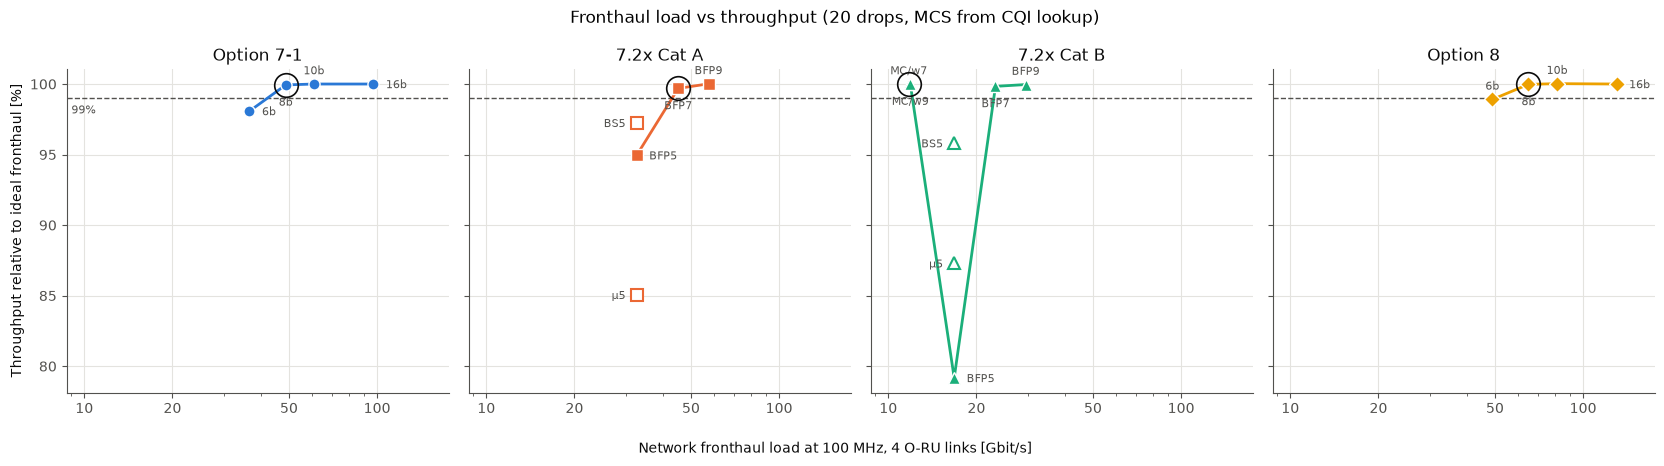

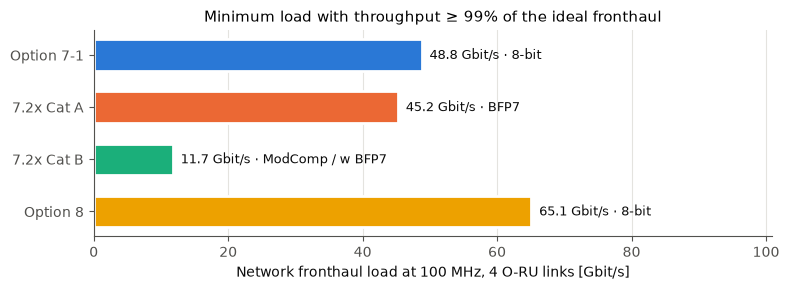

In [6]:
# Throughput vs load, one panel per split (same axes). Filled markers on the line: uniform fixed point (7-1, 8), BFP and
# modulation compression (Cat A / B); hollow: block scaling / μ-law at the same bits as BFP. Short labels: "8b" = 8-bit
# uniform fixed point, "MC/w7" = modulation compression with BFP7 weights. Ring: operating point (cheapest
# configuration with throughput ≥ THROUGHPUT_KEEP).
from matplotlib.ticker import NullFormatter
SHORT = {"fixed": "{w}b", "bfp": "BFP{w}", "block_scaling": "BS{w}", "mu_law": "μ{w}"}
short = {}
for s_, u, b in CONFIGS:
    short[(s_, config_label(s_, u, b))] = f"MC/w{b[1]}" if u[0] == "modulation" else SHORT[u[0]].format(w=u[1])
fig, axes = plt.subplots(1, len(SPLITS), figsize=(4.2 * len(SPLITS), 4.6), sharey=True, sharex=True)
all_x = [agg[k]["net100"] for k in keys]
for ax, split in zip(axes, SPLITS):
    pts = sorted((agg[(s_, l)]["net100"], 100 * agg[(s_, l)]["tput_ratio"], l) for s_, l in keys if s_ == split)
    main = [p for p in pts if not p[2].startswith(("BS", "μ"))]
    side = [p for p in pts if p[2].startswith(("BS", "μ"))]
    ax.plot([p[0] for p in main], [p[1] for p in main], "-", color=COLOR[split], lw=2, zorder=2)
    for j, (x, y, lab) in enumerate(main):           # crowded labels alternate above / below, others go right
        ax.plot(x, y, MARKER[split], ms=8, color=COLOR[split], mec="white", zorder=3)
        crowded = any(abs(np.log10(x / xo)) < 0.15 and abs(y - yo) < 1.5 for xo, yo, lo in main if lo != lab)
        offset = ((0, 7) if j % 2 == 0 else (0, -15)) if crowded else (9, -3)
        ax.annotate(short[(split, lab)], (x, y), xytext=offset, textcoords="offset points",
                    fontsize=8, color=INK2, ha="center" if crowded else "left")
    prev_y, level = None, 0
    for x, y, lab in sorted(side, key=lambda p: -p[1]):   # hollow points: labels on the left
        ax.plot(x, y, MARKER[split], ms=8, mfc="white", mec=COLOR[split], mew=1.5, zorder=3)
        level = level + 1 if prev_y is not None and prev_y - y < 2.5 else 0
        prev_y = y
        ax.annotate(short[(split, lab)], (x, y), xytext=(-8, -3 - 11 * level), textcoords="offset points",
                    fontsize=8, color=INK2, ha="right")
    if split in best:
        a = agg[(split, best[split])]
        ax.plot(a["net100"], 100 * a["tput_ratio"], "o", ms=17, mfc="none", mec=INK, mew=1.2, zorder=4)
    ax.axhline(100 * THROUGHPUT_KEEP, color=INK2, lw=1, ls="--", zorder=1)
    ax.set_xscale("log")
    ax.set_xticks([10, 20, 50, 100], ["10", "20", "50", "100"])
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlim(min(all_x) / 1.35, max(all_x) * 1.35)
    ax.set_title(SPLIT_NAME[split], color=INK)
axes[0].set_ylabel("Throughput relative to ideal fronthaul [%]")
axes[0].annotate(f"{100 * THROUGHPUT_KEEP:.0f}%", (min(all_x) / 1.3, 100 * THROUGHPUT_KEEP), xytext=(0, -11),
                 textcoords="offset points", fontsize=8, color=INK2)
fig.supxlabel(f"Network fronthaul load at 100 MHz, {NUM_ORU} O-RU links [Gbit/s]", fontsize=10, color=INK)
fig.suptitle(f"Fronthaul load vs throughput ({NUM_DROPS} drops, MCS from CQI lookup)", fontsize=12)
plt.tight_layout(); plt.show()
fig_load = fig

fig, ax = plt.subplots(figsize=(8, 0.6 + 0.6 * len(best)))
names = [s_ for s_ in SPLITS if s_ in best]
vals = [agg[(s_, best[s_])]["net100"] for s_ in names]
ax.barh(range(len(names)), vals, color=[COLOR[s_] for s_ in names], height=0.6, edgecolor="white", linewidth=2)
for i, (s_, v) in enumerate(zip(names, vals)):
    ax.text(v, i, f"  {v:.1f} Gbit/s · {best[s_]}", va="center", fontsize=9, color=INK)
ax.set_yticks(range(len(names)), [SPLIT_NAME[s_] for s_ in names]); ax.invert_yaxis()
ax.set_xlim(0, max(vals) * 1.55 if vals else 1)
ax.set_xlabel(f"Network fronthaul load at 100 MHz, {NUM_ORU} O-RU links [Gbit/s]")
ax.set_title(f"Minimum load with throughput ≥ {100 * THROUGHPUT_KEEP:.0f}% of the ideal fronthaul", fontsize=11)
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
fig_best = fig

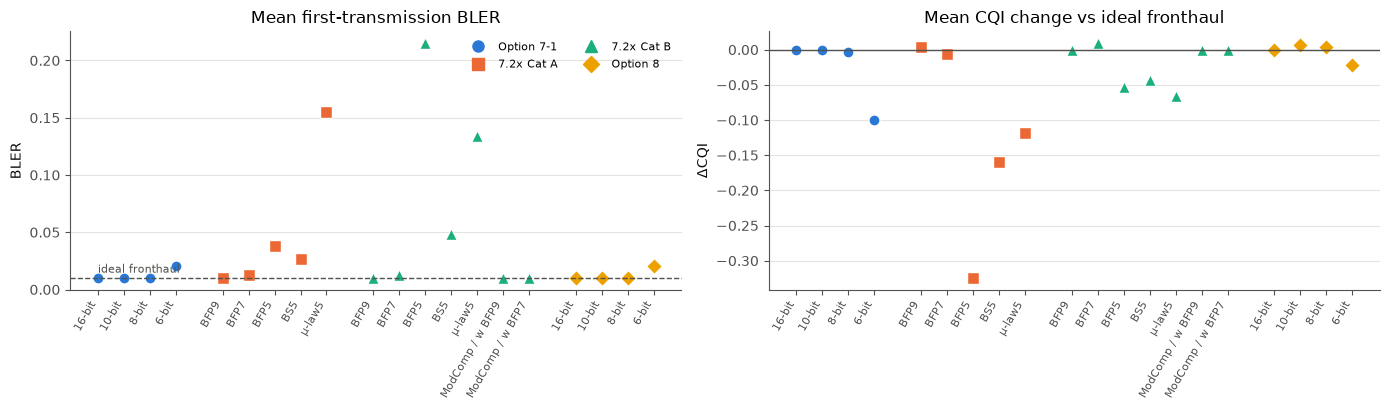

In [7]:
# Where the throughput goes: block errors (distortion the CQI did not see) and the CQI reaction (distortion it did see)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
xs, ticks, pos = [], [], 0
for split in SPLITS:
    labs = [l for s, l in keys if s == split]
    for j, lab in enumerate(labs):
        a = agg[(split, lab)]
        for ax, v in zip(axes, (a["bler"], a["dcqi"])):
            ax.plot(pos, v, MARKER[split], ms=8, color=COLOR[split], mec="white")
        ticks.append((pos, lab)); pos += 1
    pos += 0.8
for ax, title, ylab in zip(axes, ("Mean first-transmission BLER", "Mean CQI change vs ideal fronthaul"),
                           ("BLER", "ΔCQI")):
    ax.set_xticks([t[0] for t in ticks], [t[1] for t in ticks], rotation=60, ha="right", fontsize=8)
    ax.set_title(title); ax.set_ylabel(ylab); ax.grid(axis="x", visible=False)
axes[0].axhline(ref_bler, color=INK2, lw=1, ls="--")
axes[0].annotate("ideal fronthaul", (0, ref_bler), xytext=(0, 4), textcoords="offset points", fontsize=8, color=INK2)
axes[1].axhline(0, color=INK2, lw=1)
for split in SPLITS:
    axes[0].plot([], [], MARKER[split], ms=8, color=COLOR[split], label=SPLIT_NAME[split])
axes[0].legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout(); plt.show()
fig_diag = fig

## 5. Constellations at the UE

One drop, one UE. For each split three compression levels: the CQI is measured through that configuration's fronthaul,
the MCS is looked up (or forced with `CONSTELLATION_MCS`), and one CSI-RS period of data slots is sent. The dots are the
LMMSE-equalized data symbols of the UE's first layer; the crosses are the ideal constellation points. The panel text gives
the MCS, the EVM against the transmitted symbols (noise, interference, channel estimation and fronthaul distortion), the
corresponding SINR, the CRC result and the per-O-RU link load at 100 MHz.

What to look for: in 7-1, Cat A and option 8 the quantization noise is added to the precoded antenna signals and reaches
the UE as an additional, roughly Gaussian disturbance (the clouds widen). In Cat B the U-plane carries the QAM symbols
themselves: with BFP at a few bits the quantizer step becomes comparable to the QAM spacing (5-bit BFP: about 0.12 against
0.15 for unit-power 256QAM), so whole constellation points are moved onto the quantizer grid and the error is deterministic
rather than noise-like. Modulation compression keeps the points exactly (only the 15-bit scaler is quantized).

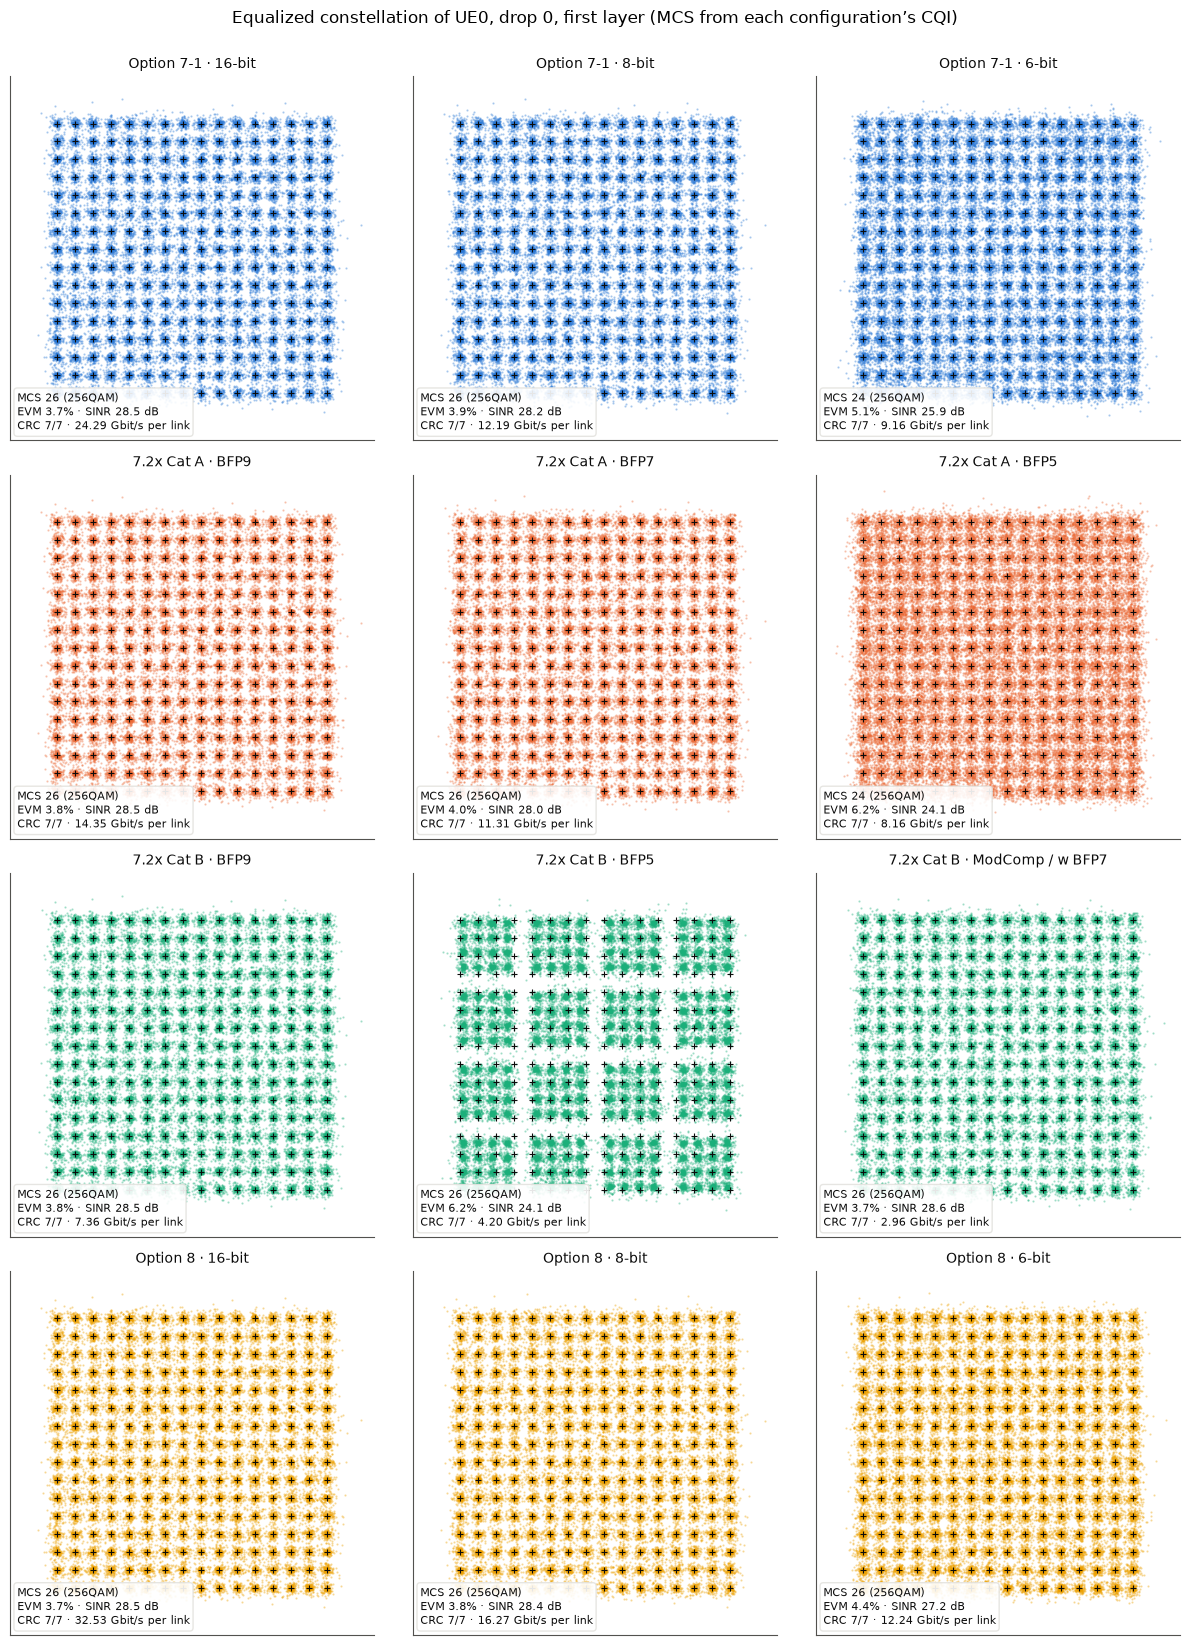

In [8]:
drop_c = CONSTELLATION_DROP
pos_c = drop_positions[drop_c]
channel.set_ue_positions(pos_c, seed=SEED + drop_c)
ref_c = ref_rows[drop_c]
k_ue = int(np.argmax(ref_c["cqi"])) if CONSTELLATION_UE is None else CONSTELLATION_UE
ncol = max(len(v) for v in CONSTELLATION_CONFIGS.values())
fig, axes = plt.subplots(len(SPLITS), ncol, figsize=(4.1 * ncol, 4.1 * len(SPLITS)))
for r, split in enumerate(SPLITS):
    cl = loops[split]
    sim = cl.sim
    for c, (up, bfw) in enumerate(CONSTELLATION_CONFIGS[split]):
        ax = axes[r, c]
        cl.set_compression(CompressionConfig(*up), comp_of(bfw))
        sionna_config.seed = SEED + drop_c
        state = sim.channel.sample(SLOTS_PER_PERIOD)
        cl.la.reset()
        cqi = (cl.measure_cqi_csirs(state) if CQI_SOURCE == "csi-rs" else cl.measure_cqi_genie(state))[0]
        mcs = cl.la.select_mcs(cqi) if CONSTELLATION_MCS is None else np.full(NUM_UE, CONSTELLATION_MCS)
        sim.set_mcs(mcs)
        tx, rx = sim.transmit_receive(SLOTS_PER_PERIOD, 0.0, state)
        x = tx.x_data[:, k_ue, 0].flatten().cpu().numpy()
        xh = rx.x_hat[:, k_ue, 0].flatten().cpu().numpy()
        evm2 = np.sum(np.abs(xh - x) ** 2) / np.sum(np.abs(x) ** 2)
        crc = rx.crc_ok[:, k_ue].cpu().numpy()
        qm = mcs_entry(MCS_TABLE, int(mcs[k_ue]))[0]
        pts = Constellation("qam", qm).points.cpu().numpy()
        ax.plot(xh.real, xh.imag, ".", ms=1.2, color=COLOR[split], alpha=0.35, rasterized=True)
        ax.plot(pts.real, pts.imag, "+", ms=4, color=INK, mew=0.8)
        lim = 1.35 * np.abs(pts.real).max()
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        load = link_load(cl.cfg, NUM_PRB_100MHZ, [mcs])["total"] / 1e9
        ax.set_title(f"{SPLIT_NAME[split]} · {config_label(split, up, bfw)}", fontsize=10, color=INK)
        ax.text(0.02, 0.02, f"MCS {int(mcs[k_ue])} ({2 ** qm}QAM)\nEVM {100 * np.sqrt(evm2):.1f}% · SINR {-db(evm2):.1f} dB\n"
                            f"CRC {int(crc.sum())}/{len(crc)} · {load:.2f} Gbit/s per link",
                transform=ax.transAxes, fontsize=8, color=INK, va="bottom",
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=GRID, alpha=0.9))
fig.suptitle(f"Equalized constellation of UE{k_ue}, drop {drop_c}, first layer "
             f"({'MCS from each configuration’s CQI' if CONSTELLATION_MCS is None else f'MCS {CONSTELLATION_MCS} forced'})",
             y=1.0, fontsize=12)
plt.tight_layout(); plt.show()
fig_const = fig

## 6. How the load scales (analytic)

The Monte Carlo part fixes the operating point of each split: the cheapest compression without throughput loss (Section 4).
With those operating points, the load of one O-RU link at 100 MHz is evaluated analytically:

- **left**: against the number of TX chains per O-RU, with the number of layers fixed (`NUM_UE` × `LAYERS_PER_UE`).
  7-1, Cat A and option 8 grow with the antennas, Cat B grows with the layers (plus its weights, which grow with both);
- **right**: against the PRB utilization (share of PRBs carrying PDSCH). 7-1 and option 8 always stream the whole carrier;
  7.2x only sends the PRBs with data.

For Cat B with modulation compression the worst case 256QAM is assumed.

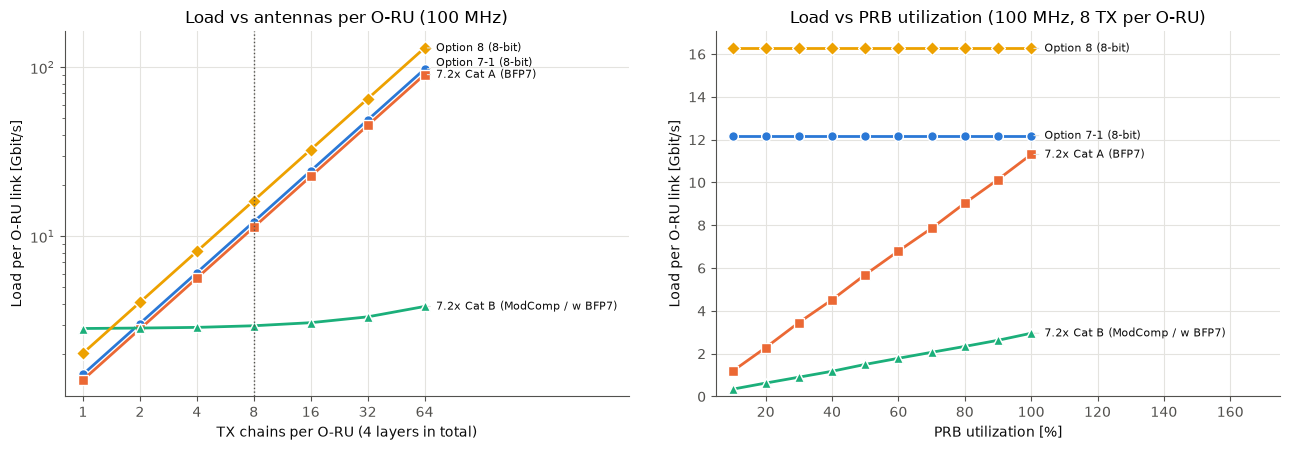

Cross-check with the TR 38.816 Annex A formulas (2×16 bit, incl. its fixed overhead, without the 1.32 margin), per O-RU link:
  7-1, 8 antenna ports, 100 MHz:  21.53 Gbit/s  | here (7-1, 16-bit, NR 273 PRB):  24.29
  7-2, 4 layers, 100 MHz:           11.11 Gbit/s  | here (Cat B, 16-bit, NR 273 PRB):  12.59
  (TR 38.816 uses the LTE subcarrier density 1200 per 20 MHz, i.e. 6000 per 100 MHz, vs 3276 for NR 100 MHz at 30 kHz.)
Saved: /home/user/Sionna-based Simulation/results/split_fronthaul_load_20261112/run_201703_drops20_seed2026


In [9]:
def op_config(split):
    """Operating point of each split: the cheapest configuration without throughput loss (else the first in CONFIGS)."""
    lab = best.get(split)
    for s, u, b in CONFIGS:
        if s == split and (lab is None or config_label(s, u, b) == lab):
            return u, b


def rate_at(split, num_ant=NUM_ORU_ANT, num_prb=NUM_PRB_100MHZ):
    up, bfw = op_config(split)
    cfg = replace(loops[split].cfg, num_oru_ant=num_ant, uplane=CompressionConfig(*up), bfw=comp_of(bfw))
    qm = [8] * NUM_UE if up[0] == "modulation" else None
    return fronthaul_rate(cfg, num_prb, qm_per_ue=qm).total / 1e9


def dodge(values, gap):
    """Direct-label positions: keep the order, push neighbours at least `gap` apart."""
    order = np.argsort(values)
    out = np.asarray(values, dtype=float).copy()
    for a, b in zip(order[:-1], order[1:]):
        out[b] = max(out[b], out[a] + gap)
    return out


ants = [1, 2, 4, 8, 16, 32, 64]
util = np.linspace(0.1, 1.0, 10)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ends = {0: [], 1: []}
for split in SPLITS:
    lab = config_label(split, *op_config(split))
    y_ant = [rate_at(split, num_ant=n) for n in ants]
    full = rate_at(split)
    y_util = [full if split in ("7-1", "8") else rate_at(split, num_prb=max(1, int(round(u * NUM_PRB_100MHZ))))
              for u in util]
    for i, (ax, xv, yv) in enumerate(((axes[0], ants, y_ant), (axes[1], 100 * util, y_util))):
        ax.plot(xv, yv, "-", color=COLOR[split], lw=2)
        ax.plot(xv, yv, MARKER[split], color=COLOR[split], ms=7, mec="white")
        ends[i].append((xv[-1], yv[-1], f"{SPLIT_NAME[split]} ({lab})"))
for i, ax in enumerate(axes):
    ys = [e[1] for e in ends[i]]
    pos = 10 ** dodge(np.log10(ys), 0.07) if i == 0 else dodge(ys, 0.045 * max(ys))
    for (x, y, text), yl in zip(ends[i], pos):
        ax.annotate(text, (x, y), xytext=(x * 1.15 if i == 0 else x + 4, yl), textcoords="data", fontsize=8,
                    color=INK, va="center", arrowprops=dict(arrowstyle="-", color=GRID, lw=0.8))
axes[0].set_xscale("log", base=2); axes[0].set_yscale("log")
axes[0].set_xticks(ants, [str(a) for a in ants]); axes[0].set_xlim(0.8, 64 * 12)
axes[0].axvline(NUM_ORU_ANT, color=INK2, lw=1, ls=":")
axes[0].set_xlabel(f"TX chains per O-RU ({base.num_layers} layers in total)"); axes[0].set_ylabel("Load per O-RU link [Gbit/s]")
axes[0].set_title("Load vs antennas per O-RU (100 MHz)")
axes[1].set_xlim(5, 175); axes[1].set_ylim(0, None)
axes[1].set_xlabel("PRB utilization [%]"); axes[1].set_ylabel("Load per O-RU link [Gbit/s]")
axes[1].set_title(f"Load vs PRB utilization (100 MHz, {NUM_ORU_ANT} TX per O-RU)")
plt.tight_layout(); plt.show()
fig_scaling = fig

print("Cross-check with the TR 38.816 Annex A formulas (2×16 bit, incl. its fixed overhead, without the 1.32 margin), per O-RU link:")
print(f"  7-1, {NUM_ORU_ANT} antenna ports, 100 MHz: {tr38816_rate('7-1', NUM_ORU_ANT, 100, with_margin=False) / 1e9:6.2f} Gbit/s"
      f"  | here (7-1, 16-bit, NR 273 PRB): {fronthaul_rate(replace(loops['7-1'].cfg, uplane=CompressionConfig('fixed', 16)), NUM_PRB_100MHZ).total / 1e9:6.2f}")
print(f"  7-2, {base.num_layers} layers, 100 MHz:          {tr38816_rate('7-2', base.num_layers, 100, with_margin=False) / 1e9:6.2f} Gbit/s"
      f"  | here (Cat B, 16-bit, NR 273 PRB): {fronthaul_rate(replace(loops['B'].cfg, uplane=CompressionConfig('none', 16), bfw=CompressionConfig('none', 16)), NUM_PRB_100MHZ).total / 1e9:6.2f}")
print("  (TR 38.816 uses the LTE subcarrier density 1200 per 20 MHz, i.e. 6000 per 100 MHz, vs 3276 for NR 100 MHz at 30 kHz.)")

if run is not None:
    for name, f in (("layout", fig_layout), ("load_vs_throughput", fig_load), ("min_load", fig_best), ("bler_dcqi", fig_diag),
                    ("constellations", fig_const), ("load_scaling", fig_scaling)):
        f.savefig(os.path.join(out_dir, f"fig_{name}.png"), dpi=150, bbox_inches="tight")
    run.finish(best=best, ideal_throughput_mbps_per_drop=ref_tput / len(ref_rows),
               summary={f"{s}|{l}": {k: float(v) for k, v in agg[(s, l)].items()} for s, l in keys})
    print("Saved:", out_dir)

## 7. Summary and modelling notes

The printed table in Section 4 and the files in the results directory hold the numbers of a run; the conclusions of the
stored run are kept in `studies/oran_baseline/experiments.md`.

**What the comparison shows by construction**
- The air interface is identical for all four splits without compression; differences come only from what is carried
  over the fronthaul and how it is quantized.
- 7-1 and option 8 scale with antennas and always stream the whole carrier; 7.2x Cat A scales with antenna streams but only
  sends PRBs with data; Cat B scales with layers plus weights. Modulation compression makes the Cat B load follow the MCS.
- With a CQI lookup and no OLLA, fronthaul distortion that the CSI-RS does not capture shows up as block errors;
  distortion that it captures lowers the CQI and the MCS. Both cost throughput, which defines the "no loss" operating point.

**Modelling simplifications**
- Static UEs, full buffer, all UEs on all PRBs; no HARQ (throughput of first transmissions); CSI reports without errors or delay.
- Full cooperation: every O-RU serves every UE with centralized BD computed from ideal CSI (TDD reciprocity) at the PRG
  centre; with absolute delays the BD nulls are exact only at the PRG centre subcarrier.
- Per-O-RU power limit by common scaling of the precoder (`per_oru_power`); fixed-point gain per antenna stream from the
  precoder (`fronthaul_agc`).
- Option 7-1: no standardized interface or compression; uniform fixed point with clipping optimized for a Gaussian signal,
  eCPRI IQ messages over Ethernet as transport (same as option 8), no C-plane. TR 38.816 adds a fixed "scheduling/control"
  overhead (121 Mbit/s at 100 MHz, 32 ports), printed as a cross-check only.
- Option 8: CPRI line coding and control words are not counted (eCPRI IQ messages instead).
- Modulation compression: one section per layer and symbol, SE 5 masks, no selective RE sending (empty REs still occupy
  bits); the only distortion is the 15-bit scaler. C-plane overhead of the DMRS section and SE 5 / SE 6 is approximate.
- The 100 MHz load is the 20 MHz configuration scaled to 273 PRB; the throughput criterion is taken from the 20 MHz simulation.